# Arduino: Pre-Test and Post-Test Analysis

This notebook examines assessment results for the Arduino workshop.

## Scoring decisions

The Q5 answer key is recorded as ABCD in both phases. Its intended meaning
is unclear, and the workbook's exact-match formula scores individual
A–D responses as incorrect. Q5 is therefore excluded from the primary
analysis pending clarification.

The primary analysis uses Q1–Q4 and includes only participants with valid
A–D responses to these four questions in both phases. Each correct answer
contributes 25 percentage points to this four-question score.

The original five-question workbook scores are reported separately for
transparency. They are not directly comparable with four-question scores
because their denominators and included participants differ.

## Interpretation

Arduino's pre-test and post-test contain related but different questions.
Comparisons describe performance on the two assessments; they do not
measure changes on identical questions or establish a causal workshop effect.

In [1]:
from pathlib import Path
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

TRACK = "arduino"
TITLE = "Arduino"

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed").is_dir()),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/processed. Open this notebook inside your project."
    )

DATA = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures" / TRACK
TABLES = ROOT / "outputs" / "tables" / TRACK

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

PRE_COLOR = "#7952B3"
POST_COLOR = "#E88932"

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Data folder:", DATA)

Data folder: c:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\data\processed


In [2]:
df = pd.read_csv(
    DATA / "arduino.csv",
    dtype={"participant_id": "string"},
)

reference = pd.read_csv(DATA / "question_reference.csv")
keys = reference.loc[reference["track"].eq(TRACK)].copy()

all_cols = [
    f"{phase}_q{q}"
    for phase in ["pre", "post"]
    for q in range(1, 6)
]

primary_cols = [
    f"{phase}_q{q}"
    for phase in ["pre", "post"]
    for q in range(1, 5)
]

workbook_cols = [
    "pre_correct_workbook",
    "post_correct_workbook",
    "pre_score_pct_workbook",
    "post_score_pct_workbook",
    "change_pp_workbook",
]

required = ["participant_id", "track", *all_cols, *workbook_cols]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

if df.empty:
    raise ValueError("The Arduino dataset is empty.")

if df["participant_id"].fillna("").str.strip().eq("").any():
    raise ValueError("Missing participant IDs.")

if df["participant_id"].duplicated().any():
    raise ValueError("Duplicate participant IDs must be resolved.")

if not df["track"].eq(TRACK).all():
    raise ValueError("The dataset contains another track.")

answers = df[all_cols].apply(
    lambda col: col.astype("string").str.strip().str.upper()
)

keys["phase"] = keys["phase"].astype(str).str.strip().str.lower()
keys["question_number"] = pd.to_numeric(
    keys["question"].astype(str).str.extract(r"(\d+)", expand=False),
    errors="raise",
).astype(int)

keys["answer_key_raw"] = (
    keys["answer_key_raw"].astype("string").str.strip().str.upper()
)

expected = {
    (phase, q)
    for phase in ["pre", "post"]
    for q in range(1, 6)
}
actual = set(zip(keys["phase"], keys["question_number"]))

if len(keys) != 10 or actual != expected:
    raise ValueError("Expected one answer key per phase and question.")

key_map = keys.set_index(
    ["phase", "question_number"]
)["answer_key_raw"]

skill_map = keys.set_index(
    ["phase", "question_number"]
)["skill"]

if not keys.loc[
    keys["question_number"].le(4), "answer_key_raw"
].isin(list("ABCD")).all():
    raise ValueError("Q1–Q4 contains an unresolved answer key.")

if not keys.loc[
    keys["question_number"].eq(5), "answer_key_raw"
].eq("ABCD").all():
    raise ValueError(
        "The Q5 key has changed. Review the scoring policy before continuing."
    )

valid = answers.isin(list("ABCD"))
complete_mask = valid[primary_cols].all(axis=1)

audit = df[["participant_id"]].copy()
audit["q1_q4_unresolved_count"] = (~valid[primary_cols]).sum(axis=1)
audit["pre_q5_response"] = answers["pre_q5"]
audit["post_q5_response"] = answers["post_q5"]
audit["included_in_primary_analysis"] = complete_mask
audit["q5_excluded_due_to_key"] = True

print(f"Total participants: {len(df)}")
print(f"Complete Q1–Q4 pairs: {complete_mask.sum()}")
print(f"Excluded from primary comparison: {(~complete_mask).sum()}")

display(keys[["phase", "question_number", "answer_key_raw", "skill"]])
display(audit.loc[~complete_mask])

Total participants: 27
Complete Q1–Q4 pairs: 26
Excluded from primary comparison: 1


,phase,question_number,answer_key_raw,skill
40,pre,1,A,Arduino structure: void setup() runs once
41,pre,2,C,"Hardware: analog input (ADC) range, 0–1023"
42,pre,3,D,Circuit design: why a resistor limits current
43,pre,4,B,Conditional logic: sensor-triggered actuator (if)
44,pre,5,ABCD,Computational thinking: decomposition & reusab...
45,post,1,A,Arduino structure: void loop() runs continuously
46,post,2,C,"Hardware: PWM output (analogWrite) range, 0–255"
47,post,3,D,Circuit design: consequence of omitting a resi...
48,post,4,B,Conditional logic: sensor-triggered actuator (...
49,post,5,ABCD,Computational thinking: pattern generalization...


,participant_id,q1_q4_unresolved_count,pre_q5_response,post_q5_response,included_in_primary_analysis,q5_excluded_due_to_key
22,E669E618,1,X,B,False,True


## Primary scores and workbook verification

Primary scores are calculated from four questions using the same
complete-response participants in both phases.

Separately, the workbook's exact-match scoring is reconstructed for all
five questions and checked against its stored scores. This verification
checks consistency with Excel; it does not validate the intended meaning
of the Q5 answer key or X responses.

In [3]:
correctness = pd.DataFrame(index=df.index)

for phase in ["pre", "post"]:
    for q in range(1, 5):
        col = f"{phase}_q{q}"
        correctness[col] = (
            answers[col].eq(key_map[(phase, q)])
            .astype("Float64")
            .where(valid[col])
        )

paired = df.loc[complete_mask, ["participant_id"]].copy()

if paired.empty:
    raise ValueError("No complete Q1–Q4 pairs are available.")

for phase in ["pre", "post"]:
    cols = [f"{phase}_q{q}" for q in range(1, 5)]
    paired[f"{phase}_correct"] = (
        correctness.loc[complete_mask, cols]
        .sum(axis=1, min_count=4)
        .astype(int)
    )
    paired[f"{phase}_score_pct"] = paired[f"{phase}_correct"] * 25

paired["change_pp"] = (
    paired["post_score_pct"] - paired["pre_score_pct"]
)

# Reconstruct Excel's exact-match scoring separately.
literal = df[["participant_id"]].copy()

for phase in ["pre", "post"]:
    literal[f"{phase}_correct"] = sum(
        answers[f"{phase}_q{q}"]
        .eq(key_map[(phase, q)])
        .fillna(False)
        .astype(int)
        for q in range(1, 6)
    )
    literal[f"{phase}_score_pct"] = literal[f"{phase}_correct"] * 20

literal["change_pp"] = (
    literal["post_score_pct"] - literal["pre_score_pct"]
)

checks = []

for calculated, stored in [
    ("pre_correct", "pre_correct_workbook"),
    ("post_correct", "post_correct_workbook"),
    ("pre_score_pct", "pre_score_pct_workbook"),
    ("post_score_pct", "post_score_pct_workbook"),
    ("change_pp", "change_pp_workbook"),
]:
    matches = np.isclose(
        literal[calculated].to_numpy(dtype=float),
        pd.to_numeric(df[stored], errors="coerce").to_numpy(dtype=float),
        atol=1e-8,
        equal_nan=False,
    )
    checks.append({
        "field": stored,
        "matching": int(matches.sum()),
        "mismatching_or_missing": int((~matches).sum()),
    })

verification = pd.DataFrame(checks)
display(verification)

if verification["mismatching_or_missing"].sum():
    raise ValueError("Workbook scoring differences found. Review before continuing.")

def summarize_scores(frame, label, denominator):
    return {
        "analysis": label,
        "participants": len(frame),
        "questions_in_denominator": denominator,
        "pre_mean_pct": frame["pre_score_pct"].mean(),
        "post_mean_pct": frame["post_score_pct"].mean(),
        "mean_change_pp": frame["change_pp"].mean(),
    }

scoring_comparison = pd.DataFrame([
    summarize_scores(paired, "Primary: complete Q1–Q4 pairs", 4),
    summarize_scores(
        literal.loc[complete_mask],
        "Workbook scoring: same participants",
        5,
    ),
    summarize_scores(
        literal,
        "Workbook scoring: all participants",
        5,
    ),
])

display(scoring_comparison.round(2))

print(
    "Q5 receives no credit under literal ABCD matching. "
    "Workbook percentages therefore have a maximum of 80% "
    "for participants selecting individual A–D answers."
)

,field,matching,mismatching_or_missing
0,pre_correct_workbook,27,0
1,post_correct_workbook,27,0
2,pre_score_pct_workbook,27,0
3,post_score_pct_workbook,27,0
4,change_pp_workbook,27,0


,analysis,participants,questions_in_denominator,pre_mean_pct,post_mean_pct,mean_change_pp
0,Primary: complete Q1–Q4 pairs,26,4,54.81,72.12,17.31
1,Workbook scoring: same participants,26,5,43.85,57.69,13.85
2,Workbook scoring: all participants,27,5,42.96,57.78,14.81


Q5 receives no credit under literal ABCD matching. Workbook percentages therefore have a maximum of 80% for participants selecting individual A–D answers.


## Overall assessment results

The following figures use only the primary four-question analysis group.

Higher or lower scores indicate differences between assessment totals.
Because the pre/post questions differ, these differences may reflect
both participant performance and differences in question difficulty.

,phase,participants,mean_correct_out_of_4,median_correct_out_of_4,sd_correct,minimum_correct,maximum_correct,mean_score_pct
0,Pre,26,2.19,2.0,0.69,1,3,54.81
1,Post,26,2.88,3.0,1.03,0,4,72.12


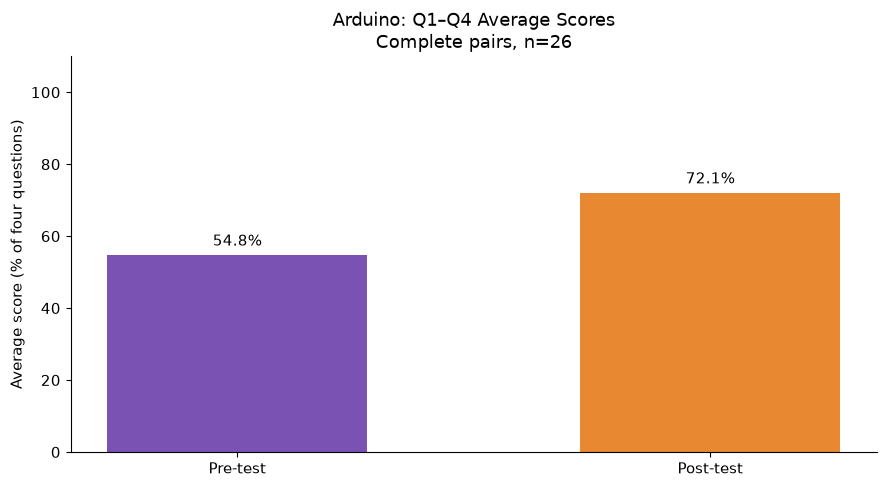

,change_group,participants,percentage
0,Higher,19,73.08
1,Unchanged,4,15.38
2,Lower,3,11.54


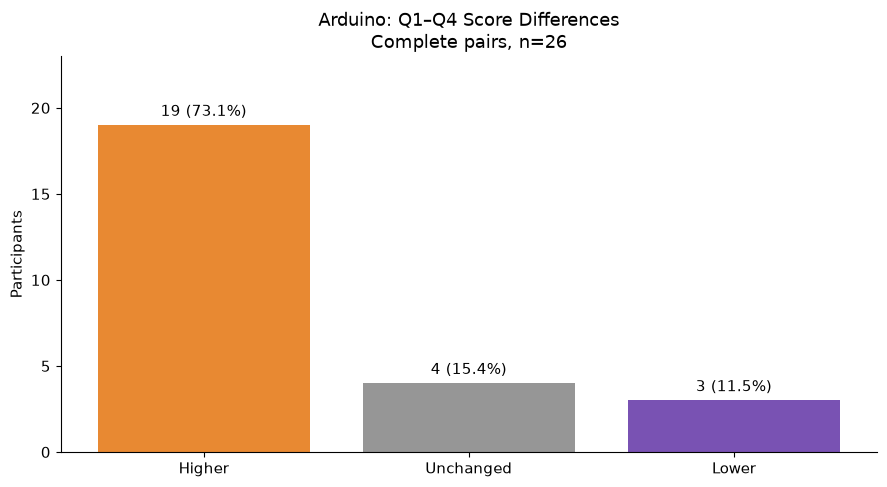

,correct_answers,pre,post
0,0,0,1
1,1,4,0
2,2,13,9
3,3,9,7
4,4,0,9


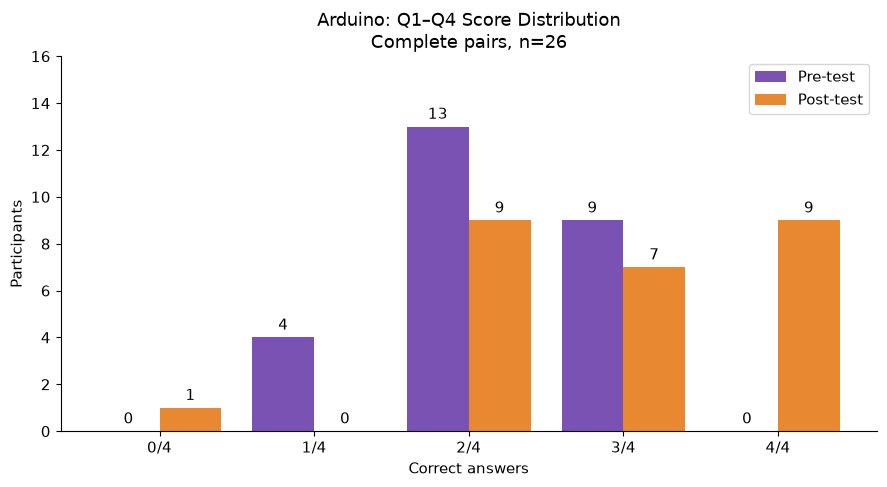

In [4]:
n = len(paired)

summary = pd.DataFrame([
    {
        "phase": phase.title(),
        "participants": n,
        "mean_correct_out_of_4": paired[f"{phase}_correct"].mean(),
        "median_correct_out_of_4": paired[f"{phase}_correct"].median(),
        "sd_correct": paired[f"{phase}_correct"].std(),
        "minimum_correct": paired[f"{phase}_correct"].min(),
        "maximum_correct": paired[f"{phase}_correct"].max(),
        "mean_score_pct": paired[f"{phase}_score_pct"].mean(),
    }
    for phase in ["pre", "post"]
])

display(summary.round(2))

# Figure 1
fig, ax = plt.subplots()
bars = ax.bar(
    ["Pre-test", "Post-test"],
    summary["mean_score_pct"],
    color=[PRE_COLOR, POST_COLOR],
    width=0.55,
)
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set_ylim(0, 110)
ax.set_ylabel("Average score (% of four questions)")
ax.set_title(f"{TITLE}: Q1–Q4 Average Scores\nComplete pairs, n={n}")
save_figure(fig, "01_primary_average_scores.png")

paired["change_group"] = np.select(
    [paired["change_pp"].gt(0), paired["change_pp"].lt(0)],
    ["Higher", "Lower"],
    default="Unchanged",
)

changes = (
    paired["change_group"].value_counts()
    .reindex(["Higher", "Unchanged", "Lower"], fill_value=0)
    .rename_axis("change_group")
    .reset_index(name="participants")
)
changes["percentage"] = changes["participants"] / n * 100
display(changes.round(2))

# Figure 2
fig, ax = plt.subplots()
bars = ax.bar(
    changes["change_group"],
    changes["participants"],
    color=[POST_COLOR, "#969696", PRE_COLOR],
)
ax.bar_label(
    bars,
    labels=[
        f"{count} ({pct:.1f}%)"
        for count, pct in zip(
            changes["participants"], changes["percentage"]
        )
    ],
    padding=4,
)
ax.set_ylim(0, changes["participants"].max() + 4)
ax.set_ylabel("Participants")
ax.yaxis.get_major_locator().set_params(integer=True)
ax.set_title(f"{TITLE}: Q1–Q4 Score Differences\nComplete pairs, n={n}")
save_figure(fig, "02_participant_score_differences.png")

distribution = pd.DataFrame({"correct_answers": range(5)})

for phase in ["pre", "post"]:
    distribution[phase] = (
        paired[f"{phase}_correct"].value_counts()
        .reindex(range(5), fill_value=0).to_numpy()
    )

display(distribution)

# Figure 3
x = np.arange(5)
fig, ax = plt.subplots()

for offset, phase, color in [
    (-0.2, "pre", PRE_COLOR),
    (0.2, "post", POST_COLOR),
]:
    bars = ax.bar(
        x + offset,
        distribution[phase],
        width=0.4,
        label=f"{phase.title()}-test",
        color=color,
    )
    ax.bar_label(bars, padding=3)

ax.set_xticks(x, [f"{q}/4" for q in x])
ax.set_ylim(0, distribution[["pre", "post"]].to_numpy().max() + 3)
ax.set_xlabel("Correct answers")
ax.set_ylabel("Participants")
ax.yaxis.get_major_locator().set_params(integer=True)
ax.set_title(f"{TITLE}: Q1–Q4 Score Distribution\nComplete pairs, n={n}")
ax.legend()
save_figure(fig, "03_primary_score_distribution.png")

## Question-level assessment snapshots

Pre-test and post-test correct-answer rates are shown with their actual
skill descriptions. Both phases use the same primary analysis group.

For example, Q1 assesses setup() before the workshop and loop() after
the workshop. A difference between these rates must not be described
as improvement on the same question.

Q5 is excluded from correctness calculations. Its recorded answer choices
are displayed separately to support review of the unresolved answer key.

,question,participants,pre_skill,post_skill,pre_correct,post_correct,pre_pct,post_pct,difference_pp_different_items
0,Q1,26,Arduino structure: void setup() runs once,Arduino structure: void loop() runs continuously,1,20,3.85,76.92,73.08
1,Q2,26,"Hardware: analog input (ADC) range, 0–1023","Hardware: PWM output (analogWrite) range, 0–255",9,15,34.62,57.69,23.08
2,Q3,26,Circuit design: why a resistor limits current,Circuit design: consequence of omitting a resi...,26,23,100.00,88.46,-11.54
3,Q4,26,Conditional logic: sensor-triggered actuator (if),Conditional logic: sensor-triggered actuator (...,21,17,80.77,65.38,-15.38


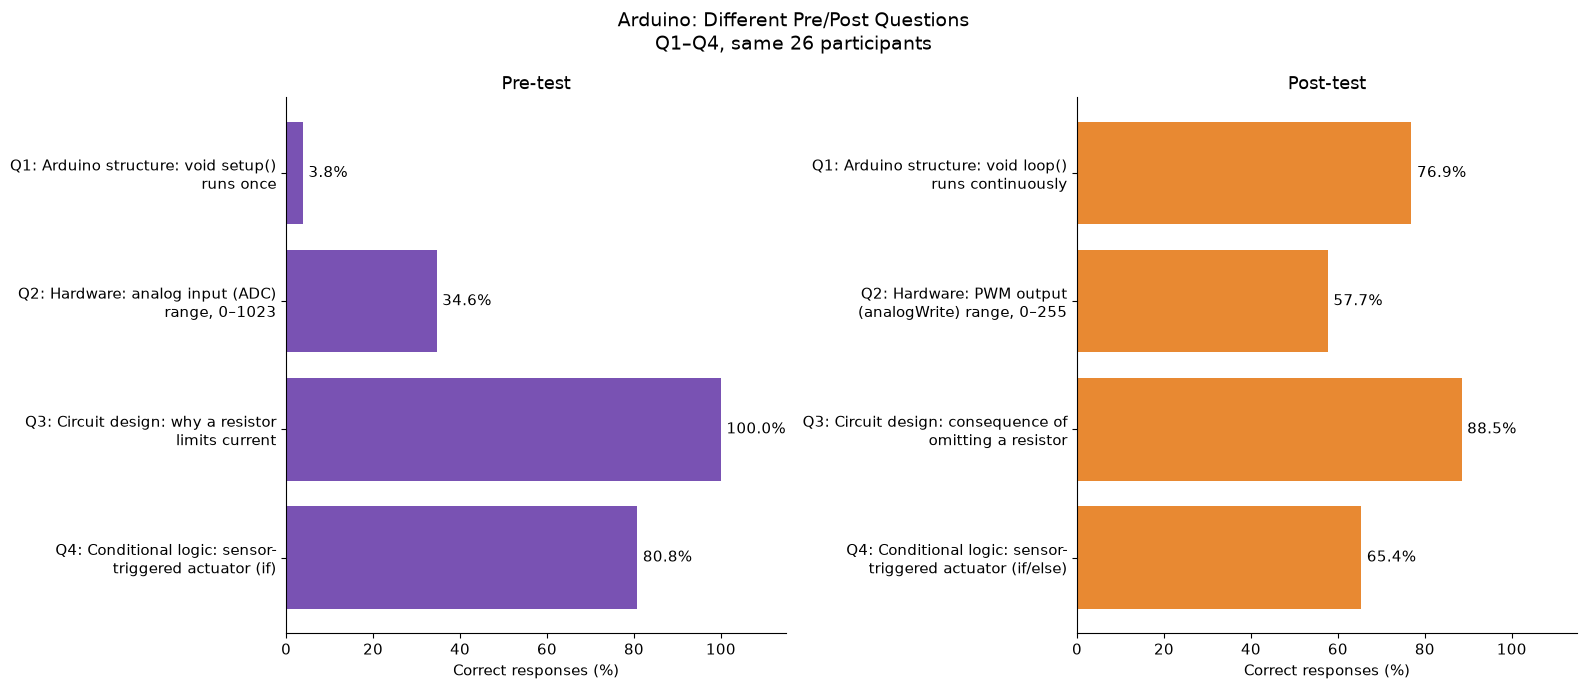

,response,pre,post
0,A,10,9
1,B,12,14
2,C,3,4
3,D,0,0
4,X,2,0


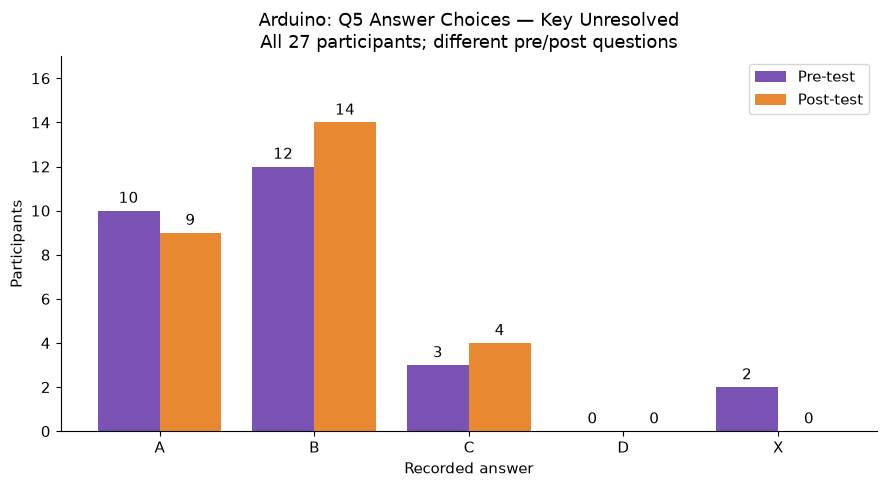

In [5]:
item_rows = []

for q in range(1, 5):
    pre = correctness.loc[complete_mask, f"pre_q{q}"].astype(int)
    post = correctness.loc[complete_mask, f"post_q{q}"].astype(int)

    item_rows.append({
        "question": f"Q{q}",
        "participants": n,
        "pre_skill": skill_map[("pre", q)],
        "post_skill": skill_map[("post", q)],
        "pre_correct": int(pre.sum()),
        "post_correct": int(post.sum()),
        "pre_pct": pre.mean() * 100,
        "post_pct": post.mean() * 100,
        "difference_pp_different_items": (post.mean() - pre.mean()) * 100,
    })

items = pd.DataFrame(item_rows)
display(items.round(2))

# Figure 4: separate panels preserve the actual question descriptions.
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, phase, color in zip(
    axes, ["pre", "post"], [PRE_COLOR, POST_COLOR]
):
    labels = [
        f"{row['question']}: {fill(str(row[f'{phase}_skill']), 32)}"
        for _, row in items.iterrows()
    ]
    bars = ax.barh(
        np.arange(4),
        items[f"{phase}_pct"],
        color=color,
    )
    ax.bar_label(bars, fmt="%.1f%%", padding=4)
    ax.set_yticks(np.arange(4), labels)
    ax.invert_yaxis()
    ax.set_xlim(0, 115)
    ax.set_xlabel("Correct responses (%)")
    ax.set_title(f"{phase.title()}-test")

fig.suptitle(
    f"{TITLE}: Different Pre/Post Questions\n"
    f"Q1–Q4, same {n} participants",
    fontsize=14,
)
save_figure(fig, "04_question_snapshots.png")

# Preserve any unusual Q5 values rather than silently dropping them.
q5_answers = answers[["pre_q5", "post_q5"]].fillna("(missing)")
observed = set(q5_answers.to_numpy().ravel())
categories = list("ABCD") + sorted(observed - set("ABCD"))

q5_distribution = pd.DataFrame({"response": categories})

for phase in ["pre", "post"]:
    q5_distribution[phase] = (
        q5_answers[f"{phase}_q5"].value_counts()
        .reindex(categories, fill_value=0).to_numpy()
    )

display(q5_distribution)

# Figure 5: response choices, not correctness
x = np.arange(len(categories))
fig, ax = plt.subplots()

for offset, phase, color in [
    (-0.2, "pre", PRE_COLOR),
    (0.2, "post", POST_COLOR),
]:
    bars = ax.bar(
        x + offset,
        q5_distribution[phase],
        width=0.4,
        color=color,
        label=f"{phase.title()}-test",
    )
    ax.bar_label(bars, padding=3)

ax.set_xticks(x, categories)
ax.set_ylim(0, q5_distribution[["pre", "post"]].to_numpy().max() + 3)
ax.set_xlabel("Recorded answer")
ax.set_ylabel("Participants")
ax.yaxis.get_major_locator().set_params(integer=True)
ax.set_title(
    f"{TITLE}: Q5 Answer Choices — Key Unresolved\n"
    f"All {len(df)} participants; different pre/post questions"
)
ax.legend()
save_figure(fig, "05_q5_answer_choices.png")

In [6]:
pre_mean = paired["pre_score_pct"].mean()
post_mean = paired["post_score_pct"].mean()
mean_change = paired["change_pp"].mean()

higher = int(paired["change_pp"].gt(0).sum())
unchanged = int(paired["change_pp"].eq(0).sum())
lower = int(paired["change_pp"].lt(0).sum())

item_lines = "\n\n".join(
    f"**{r.question}**\n"
    f"- Pre-test: {r.pre_skill} — "
    f"**{r.pre_correct}/{n} ({r.pre_pct:.1f}%)**.\n"
    f"- Post-test: {r.post_skill} — "
    f"**{r.post_correct}/{n} ({r.post_pct:.1f}%)**."
    for r in items.itertuples()
)

original = scoring_comparison.iloc[2]

findings_md = f"""
## Overall findings

The dataset contains **{len(df)} participants**. The primary analysis uses
**{n} participants** with valid Q1–Q4 responses in both phases.
**{len(df) - n} participant(s)** are excluded from this comparison because
of unresolved responses within Q1–Q4.

Q5 is excluded for everyone because its answer key is recorded as ABCD
and its intended scoring has not been confirmed. A Q5 response of X
does not independently exclude a participant from the Q1–Q4 analysis.

### Primary four-question results

Average scores were **{pre_mean:.1f}% before** and
**{post_mean:.1f}% after**, a difference of
**{mean_change:+.1f} percentage points**.

- Higher post-test scores: **{higher} ({higher / n:.1%})**
- Unchanged scores: **{unchanged} ({unchanged / n:.1%})**
- Lower post-test scores: **{lower} ({lower / n:.1%})**

These are paired participant totals on different assessment questions.
They should not be interpreted as changes on identical items.

### Question-level snapshots

{item_lines}

### Original workbook scoring

For all **{int(original["participants"])} participants**, the workbook's
five-question scoring produces averages of
**{original["pre_mean_pct"]:.2f}% before** and
**{original["post_mean_pct"]:.2f}% after**, with a difference of
**{original["mean_change_pp"]:+.2f} percentage points**.

Under its exact-match formula, individual A–D responses do not match the
Q5 key ABCD. This leaves Q5 with zero credited responses. Agreement with
these formulas confirms scoring consistency, not the validity of the key.

The primary four-question scores and original workbook scores use
different denominators. They must remain clearly labeled in any report.

## Limitations

The assessment is short, the sample is small, and there is no comparison
group. The pre/post questions differ, so differences in difficulty may
contribute to score differences.

The primary analysis covers only four questions and omits the content
represented by Q5. Excluding unresolved Q1–Q4 responses may also affect
how well the results represent all participants.

These findings do not establish long-term retention, complete Arduino
proficiency, or a causal workshop effect.
"""

display(Markdown(findings_md))


## Overall findings

The dataset contains **27 participants**. The primary analysis uses
**26 participants** with valid Q1–Q4 responses in both phases.
**1 participant(s)** are excluded from this comparison because
of unresolved responses within Q1–Q4.

Q5 is excluded for everyone because its answer key is recorded as ABCD
and its intended scoring has not been confirmed. A Q5 response of X
does not independently exclude a participant from the Q1–Q4 analysis.

### Primary four-question results

Average scores were **54.8% before** and
**72.1% after**, a difference of
**+17.3 percentage points**.

- Higher post-test scores: **19 (73.1%)**
- Unchanged scores: **4 (15.4%)**
- Lower post-test scores: **3 (11.5%)**

These are paired participant totals on different assessment questions.
They should not be interpreted as changes on identical items.

### Question-level snapshots

**Q1**
- Pre-test: Arduino structure: void setup() runs once — **1/26 (3.8%)**.
- Post-test: Arduino structure: void loop() runs continuously — **20/26 (76.9%)**.

**Q2**
- Pre-test: Hardware: analog input (ADC) range, 0–1023 — **9/26 (34.6%)**.
- Post-test: Hardware: PWM output (analogWrite) range, 0–255 — **15/26 (57.7%)**.

**Q3**
- Pre-test: Circuit design: why a resistor limits current — **26/26 (100.0%)**.
- Post-test: Circuit design: consequence of omitting a resistor — **23/26 (88.5%)**.

**Q4**
- Pre-test: Conditional logic: sensor-triggered actuator (if) — **21/26 (80.8%)**.
- Post-test: Conditional logic: sensor-triggered actuator (if/else) — **17/26 (65.4%)**.

### Original workbook scoring

For all **27 participants**, the workbook's
five-question scoring produces averages of
**42.96% before** and
**57.78% after**, with a difference of
**+14.81 percentage points**.

Under its exact-match formula, individual A–D responses do not match the
Q5 key ABCD. This leaves Q5 with zero credited responses. Agreement with
these formulas confirms scoring consistency, not the validity of the key.

The primary four-question scores and original workbook scores use
different denominators. They must remain clearly labeled in any report.

## Limitations

The assessment is short, the sample is small, and there is no comparison
group. The pre/post questions differ, so differences in difficulty may
contribute to score differences.

The primary analysis covers only four questions and omits the content
represented by Q5. Excluding unresolved Q1–Q4 responses may also affect
how well the results represent all participants.

These findings do not establish long-term retention, complete Arduino
proficiency, or a causal workshop effect.


In [7]:
lowest_post = items.loc[items["post_pct"].eq(items["post_pct"].min())]

priority_text = "\n".join(
    f"- **{r.question}: {r.post_skill}** — "
    f"{r.post_correct} of {n} correct ({r.post_pct:.1f}%)."
    for r in lowest_post.itertuples()
)

recommendations_md = f"""
## Recommendations

### Resolve the Q5 key

Check the original pre-test and post-test questions and their scoring
instructions. Confirm whether ABCD represents multiple acceptable
answers, a multiple-selection requirement, or a recording error.

Do not select an interpretation solely because it produces higher scores.
After clarification, document the approved rule and recompute the results.

### Review unresolved responses

Confirm the meaning of X using the original records or the data owner.
Preserve the original values and document any correction.

### Reinforce the lowest post-test item results

{priority_text}

Use practical exercises that connect Arduino program structure, input
and output ranges, resistors, and conditional decisions. Explain the
differences between setup() and loop(), and between analogRead() and
analogWrite(), using short examples and code tracing.

### Improve future assessment comparisons

Use identical or demonstrably comparable pre/post questions when the
goal is to measure change. Include more than one question per skill
and a practical task where possible.

### Later prediction analysis

A provisional model can predict the post-test Q1–Q4 total from pre-test
Q1–Q4 responses. Clearly label its target as a score out of four.

Keep post-test answers and score differences out of the input features.
Evaluate on held-out participants and compare against simple baselines,
including the training-group mean and the participant's pre-test score.

With only {n} complete pairs, predictive results are exploratory.
Resolve Q5 before making claims about prediction of the full assessment.
"""

display(Markdown(recommendations_md))


## Recommendations

### Resolve the Q5 key

Check the original pre-test and post-test questions and their scoring
instructions. Confirm whether ABCD represents multiple acceptable
answers, a multiple-selection requirement, or a recording error.

Do not select an interpretation solely because it produces higher scores.
After clarification, document the approved rule and recompute the results.

### Review unresolved responses

Confirm the meaning of X using the original records or the data owner.
Preserve the original values and document any correction.

### Reinforce the lowest post-test item results

- **Q2: Hardware: PWM output (analogWrite) range, 0–255** — 15 of 26 correct (57.7%).

Use practical exercises that connect Arduino program structure, input
and output ranges, resistors, and conditional decisions. Explain the
differences between setup() and loop(), and between analogRead() and
analogWrite(), using short examples and code tracing.

### Improve future assessment comparisons

Use identical or demonstrably comparable pre/post questions when the
goal is to measure change. Include more than one question per skill
and a practical task where possible.

### Later prediction analysis

A provisional model can predict the post-test Q1–Q4 total from pre-test
Q1–Q4 responses. Clearly label its target as a score out of four.

Keep post-test answers and score differences out of the input features.
Evaluate on held-out participants and compare against simple baselines,
including the training-group mean and the participant's pre-test score.

With only 26 complete pairs, predictive results are exploratory.
Resolve Q5 before making claims about prediction of the full assessment.


In [9]:
interpretation_md = """
## Interpretation of the results

For the 26 participants with complete Q1–Q4 responses, average scores
increased from 54.81% to 72.12%. This corresponds to an increase from
2.19 to 2.88 correct answers out of four.

Nineteen participants scored higher on the post-test. Nine answered
all four post-test questions correctly, compared with none on the
pre-test. However, one participant scored zero on the post-test,
showing that outcomes varied.

### Priorities for reinforcement

The lowest post-test correctness was on the PWM output-range question:
15 of 26 participants answered correctly (57.7%). The conditional
if/else question was next lowest, with 17 correct responses (65.4%).
These items suggest priorities for further practice.

The resistor question had the highest post-test correctness:
23 of 26 participants answered correctly (88.5%).

### Interpret different questions carefully

Q1 had 3.85% correctness before and 76.92% after, but the questions
tested setup() and loop(), respectively. This difference cannot be
described as a measured improvement on the same question.

Likewise, lower post-test correctness on the resistor and conditional
logic questions does not by itself establish that participants lost
knowledge, because the questions differed between assessments.

### Keep scoring methods separate

For the same 26 participants, four-question averages were 54.81% and
72.12%, while the workbook's five-question averages were 43.85% and
57.69%. This difference comes from the denominator: the workbook
includes Q5 while awarding no credit for individual A–D responses.

Excluding Q5 changes the score scale and assessed content. It does
not represent additional learning. The four-question results remain
provisional until the intended Q5 scoring is confirmed.
"""

findings_md = (
    findings_md.split("\n## Interpretation of the results")[0].rstrip()
    + "\n\n"
    + interpretation_md.strip()
)

display(Markdown(interpretation_md))
exports = {
    "participant_audit": audit,
    "primary_q1_q4_participant_scores": paired,
    "primary_q1_q4_summary": summary,
    "primary_participant_changes": changes,
    "primary_score_distribution": distribution,
    "question_snapshots": items,
    "q5_answer_distribution": q5_distribution,
    "scoring_comparison": scoring_comparison,
    "workbook_verification": verification,
    "workbook_literal_scores": literal,
}

for name, table in exports.items():
    table.to_csv(TABLES / f"{TRACK}_{name}.csv", index=False)

findings_path = TABLES / f"{TRACK}_findings.md"
findings_path.write_text(
    findings_md + "\n\n" + recommendations_md,
    encoding="utf-8",
)

print(f"Saved {len(exports)} result tables.")
print("Figures:", FIGURES)
print("Findings:", findings_path)


## Interpretation of the results

For the 26 participants with complete Q1–Q4 responses, average scores
increased from 54.81% to 72.12%. This corresponds to an increase from
2.19 to 2.88 correct answers out of four.

Nineteen participants scored higher on the post-test. Nine answered
all four post-test questions correctly, compared with none on the
pre-test. However, one participant scored zero on the post-test,
showing that outcomes varied.

### Priorities for reinforcement

The lowest post-test correctness was on the PWM output-range question:
15 of 26 participants answered correctly (57.7%). The conditional
if/else question was next lowest, with 17 correct responses (65.4%).
These items suggest priorities for further practice.

The resistor question had the highest post-test correctness:
23 of 26 participants answered correctly (88.5%).

### Interpret different questions carefully

Q1 had 3.85% correctness before and 76.92% after, but the questions
tested setup() and loop(), respectively. This difference cannot be
described as a measured improvement on the same question.

Likewise, lower post-test correctness on the resistor and conditional
logic questions does not by itself establish that participants lost
knowledge, because the questions differed between assessments.

### Keep scoring methods separate

For the same 26 participants, four-question averages were 54.81% and
72.12%, while the workbook's five-question averages were 43.85% and
57.69%. This difference comes from the denominator: the workbook
includes Q5 while awarding no credit for individual A–D responses.

Excluding Q5 changes the score scale and assessed content. It does
not represent additional learning. The four-question results remain
provisional until the intended Q5 scoring is confirmed.


Saved 10 result tables.
Figures: c:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\figures\arduino
Findings: c:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\tables\arduino\arduino_findings.md
